In [21]:
import os
import sys
import platform
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.preprocessing import MinMaxScaler

In [ ]:
plot_dir = r'D:/Research Paper/Image'
os.makedirs(plot_dir, exist_ok=True)

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(os.path.join(plot_dir, filename), dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
RANDOM_STATE = 42
RUL_CAP = 125
N_OP_CONDITIONS = 6
SENSOR_SELECTED = 21

sensor_mapping = {
    'op_setting_1': 'altitude',
    'op_setting_2': 'mach_num',
    'op_setting_3': 'sea_lv_temp',
    'sensor_1': 'T2',
    'sensor_2': 'T24',
    'sensor_3': 'T30',
    'sensor_4': 'T50',
    'sensor_5': 'P2',
    'sensor_6': 'P15',
    'sensor_7': 'P30',
    'sensor_8': 'Nf',
    'sensor_9': 'Nc',
    'sensor_10': 'epr',
    'sensor_11': 'Ps30',
    'sensor_12': 'phi',
    'sensor_13': 'NRf',
    'sensor_14': 'NRc',
    'sensor_15': 'BPR',
    'sensor_16': 'farB',
    'sensor_17': 'htBleed',
    'sensor_18': 'Nf_dmd',
    'sensor_19': 'PCNfR_dmd',
    'sensor_20': 'W31',
    'sensor_21': 'W32'
}

cols_data = (['unit_id', 'cycle'] +
        [f'op_setting_{i}' for i in range(1,4)] +
        [f'sensor_{i}' for i in range(1,22)])

sensor_cols = ['T2', 'T24', 'T30', 'T50',
          'P2', 'P15', 'P30', 'Nf',
          'Nc', 'epr', 'Ps30', 'phi',
          'NRf', 'NRc', 'BPR', 'farB',
          'htBleed', 'Nf_dmd', 'PCNfR_dmd',
          'W31', 'W32']

op_cols = ['altitude','mach_num','sea_lv_temp']

meta_cols = ['unit_id','cycle','op_condition','RUL']

train_acq = pd.read_csv(
    r"D:/Research Paper/Data/C-MAPSS/train_FD004.txt",
    sep = ' ', header=None
)

test_acq = pd.read_csv(
    r"D:/Research Paper/Data/C-MAPSS/test_FD004.txt",
    sep = ' ', header=None
)

rul_acq = pd.read_csv(
    r"D:/Research Paper/Data/C-MAPSS/RUL_FD004.txt",
    header=None, names = ['RUL_init']
)

train_acq = train_acq.dropna(axis=1)
test_acq = test_acq.dropna(axis=1)
rul_acq = rul_acq.dropna().reset_index(drop=True)

train_acq.columns = cols_data
test_acq.columns = cols_data

train_acq = train_acq.rename(columns=sensor_mapping)
test_acq = test_acq.rename(columns=sensor_mapping)

max_cycle = train_acq.groupby('unit_id')['cycle'].max().reset_index()
max_cycle.columns = ['unit_id','max_cycle']

train_acq = train_acq.merge(max_cycle, on ='unit_id')

train_acq['RUL'] = train_acq['max_cycle'] - train_acq['cycle']

train_acq.drop(columns=['max_cycle'], inplace = True)

test_acq.columns = test_acq.columns.astype(str)
cols_to_drop = [
    c for c in test_acq.columns if 'max_cycle' in c.lower() or 'rul' in c.lower()
    ]

test_acq = test_acq.drop(columns=cols_to_drop)

max_cycle = test_acq.groupby('unit_id')['cycle'].max().reset_index(name='max_cycle')
test_acq = test_acq.merge(max_cycle, on = 'unit_id')
test_acq = test_acq.merge(rul_acq, left_on='unit_id', right_index=True)

test_acq['RUL'] = test_acq['RUL_init'] + (test_acq['max_cycle'] - test_acq['cycle'])

test_acq = test_acq.drop(columns = ['max_cycle', 'RUL_init'])

train_s = train_acq.copy()
test_s = test_acq.copy()

for df in [train_s, test_s]:
    df['altitude'] = df['altitude'].round(1)
    df['mach_num'] = df['mach_num'].round(2)
    df['sea_lv_temp'] = df['sea_lv_temp'].round(0)

op_condition_map = (
    train_s[op_cols]
    .drop_duplicates()
    .sort_values(op_cols)
    .reset_index(drop=True)
)

op_condition_map['op_condition'] = op_condition_map.index

train_s = train_s.merge(op_condition_map, on = op_cols, how = 'left')
test_s = test_s.merge(op_condition_map, on = op_cols, how = 'left')

train_sc = train_s.copy()
test_sc = test_s.copy()

scaler_sensor_per_cond = {}

for cond in sorted(train_s['op_condition'].unique()):

    idx_train = train_s['op_condition'] == cond
    idx_test = test_s['op_condition'] == cond

    scaler = MinMaxScaler()
    scaler.fit(train_sc.loc[idx_train, sensor_cols])

    train_sc.loc[idx_train, sensor_cols] = scaler.transform(train_s.loc[idx_train, sensor_cols])
    if idx_test.sum() > 0:
        test_sc.loc[idx_test, sensor_cols] = scaler.transform(test_s.loc[idx_test, sensor_cols])

    scaler_sensor_per_cond[cond] = scaler

scaler_op_global = MinMaxScaler()
scaler_op_global.fit(train_s[op_cols])

train_sc[op_cols] = scaler_op_global.transform(train_s[op_cols])
test_sc[op_cols] = scaler_op_global.transform(test_s[op_cols])

train_rul_cap = train_sc.copy()
test_rul_cap = test_sc.copy()

def apply_rul_clipping(df, rul_max=RUL_CAP):
    df = df.copy()
    df['RUL'] = df['RUL'].clip(upper=RUL_CAP)
    return df

train_rul_cap = apply_rul_clipping(train_rul_cap, rul_max=RUL_CAP)
test_rul_cap = apply_rul_clipping(test_rul_cap,  rul_max=RUL_CAP)

def build_temporal_features(df, sensor_cols, unit_col='unit_id', cycle_col='cycle'):
    df = df.sort_values([unit_col, cycle_col]).copy()
    new_features = {}

    for sensor in sensor_cols:
        g = df.groupby(unit_col)[sensor]
        new_features[f'{sensor}_lag1']    = g.shift(1)
        new_features[f'{sensor}_rmean10'] = g.transform(lambda x: x.rolling(10, min_periods=1).mean())
        new_features[f'{sensor}_ewm3']    = g.transform(lambda x: x.ewm(alpha=0.3, adjust=False).mean())
        new_features[f'{sensor}_rstd10']  = g.transform(lambda x: x.rolling(10, min_periods=1).std())
        new_features[f'{sensor}_max10']  = g.transform(lambda x: x.rolling(10, min_periods=1).max())
        new_features[f'{sensor}_min10']  = g.transform(lambda x: x.rolling(10, min_periods=1).min())
    return pd.concat([df, pd.DataFrame(new_features, index=df.index)], axis=1)

train_model = build_temporal_features(train_rul_cap, sensor_cols)
test_model  = build_temporal_features(test_rul_cap,  sensor_cols)

train_model = train_model.fillna(0)
test_model  = test_model.fillna(0)

groups = train_model['unit_id'] 

drop_cols = ['unit_id', 'cycle', 'op_condition', 'RUL'] 

X_train = train_model.drop(columns=drop_cols)
y_train = train_model['RUL']

X_test  = test_model.drop(columns=drop_cols)
y_test  = test_model['RUL']

In [4]:
RED    = '#E74C3C'
GREEN  = '#27AE60'
YELLOW = '#F1C40F'
NAVY   = '#1A5276'
AMBER  = '#7D6608'
STEEL  = '#566573'
LGRAY  = '#AAB7B8'

mpl.rcParams.update({
    'font.family'       : 'DejaVu Sans',
    'font.size'         : 10,
    'axes.titlesize'    : 10,
    'axes.titleweight'  : 'bold',
    'axes.labelsize'    : 9,
    'axes.labelcolor'   : STEEL,
    'axes.linewidth'    : 0.8,
    'axes.edgecolor'    : STEEL,
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'axes.grid'         : True,
    'grid.color'        : LGRAY,
    'grid.linewidth'    : 0.4,
    'grid.linestyle'    : '--',
    'grid.alpha'        : 0.4,
    'xtick.labelsize'   : 8,
    'ytick.labelsize'   : 8,
    'xtick.color'       : STEEL,
    'ytick.color'       : STEEL,
    'legend.fontsize'   : 8,
    'legend.framealpha' : 0.85,
    'legend.edgecolor'  : LGRAY,
    'figure.dpi'        : 300,
    'savefig.dpi'       : 300,
    'savefig.bbox'      : 'tight',
    'savefig.pad_inches': 0.08,
})

SENSOR_SHOW = ['T24', 'T50', 'P30', 'Nf', 'Ps30', 'NRc']

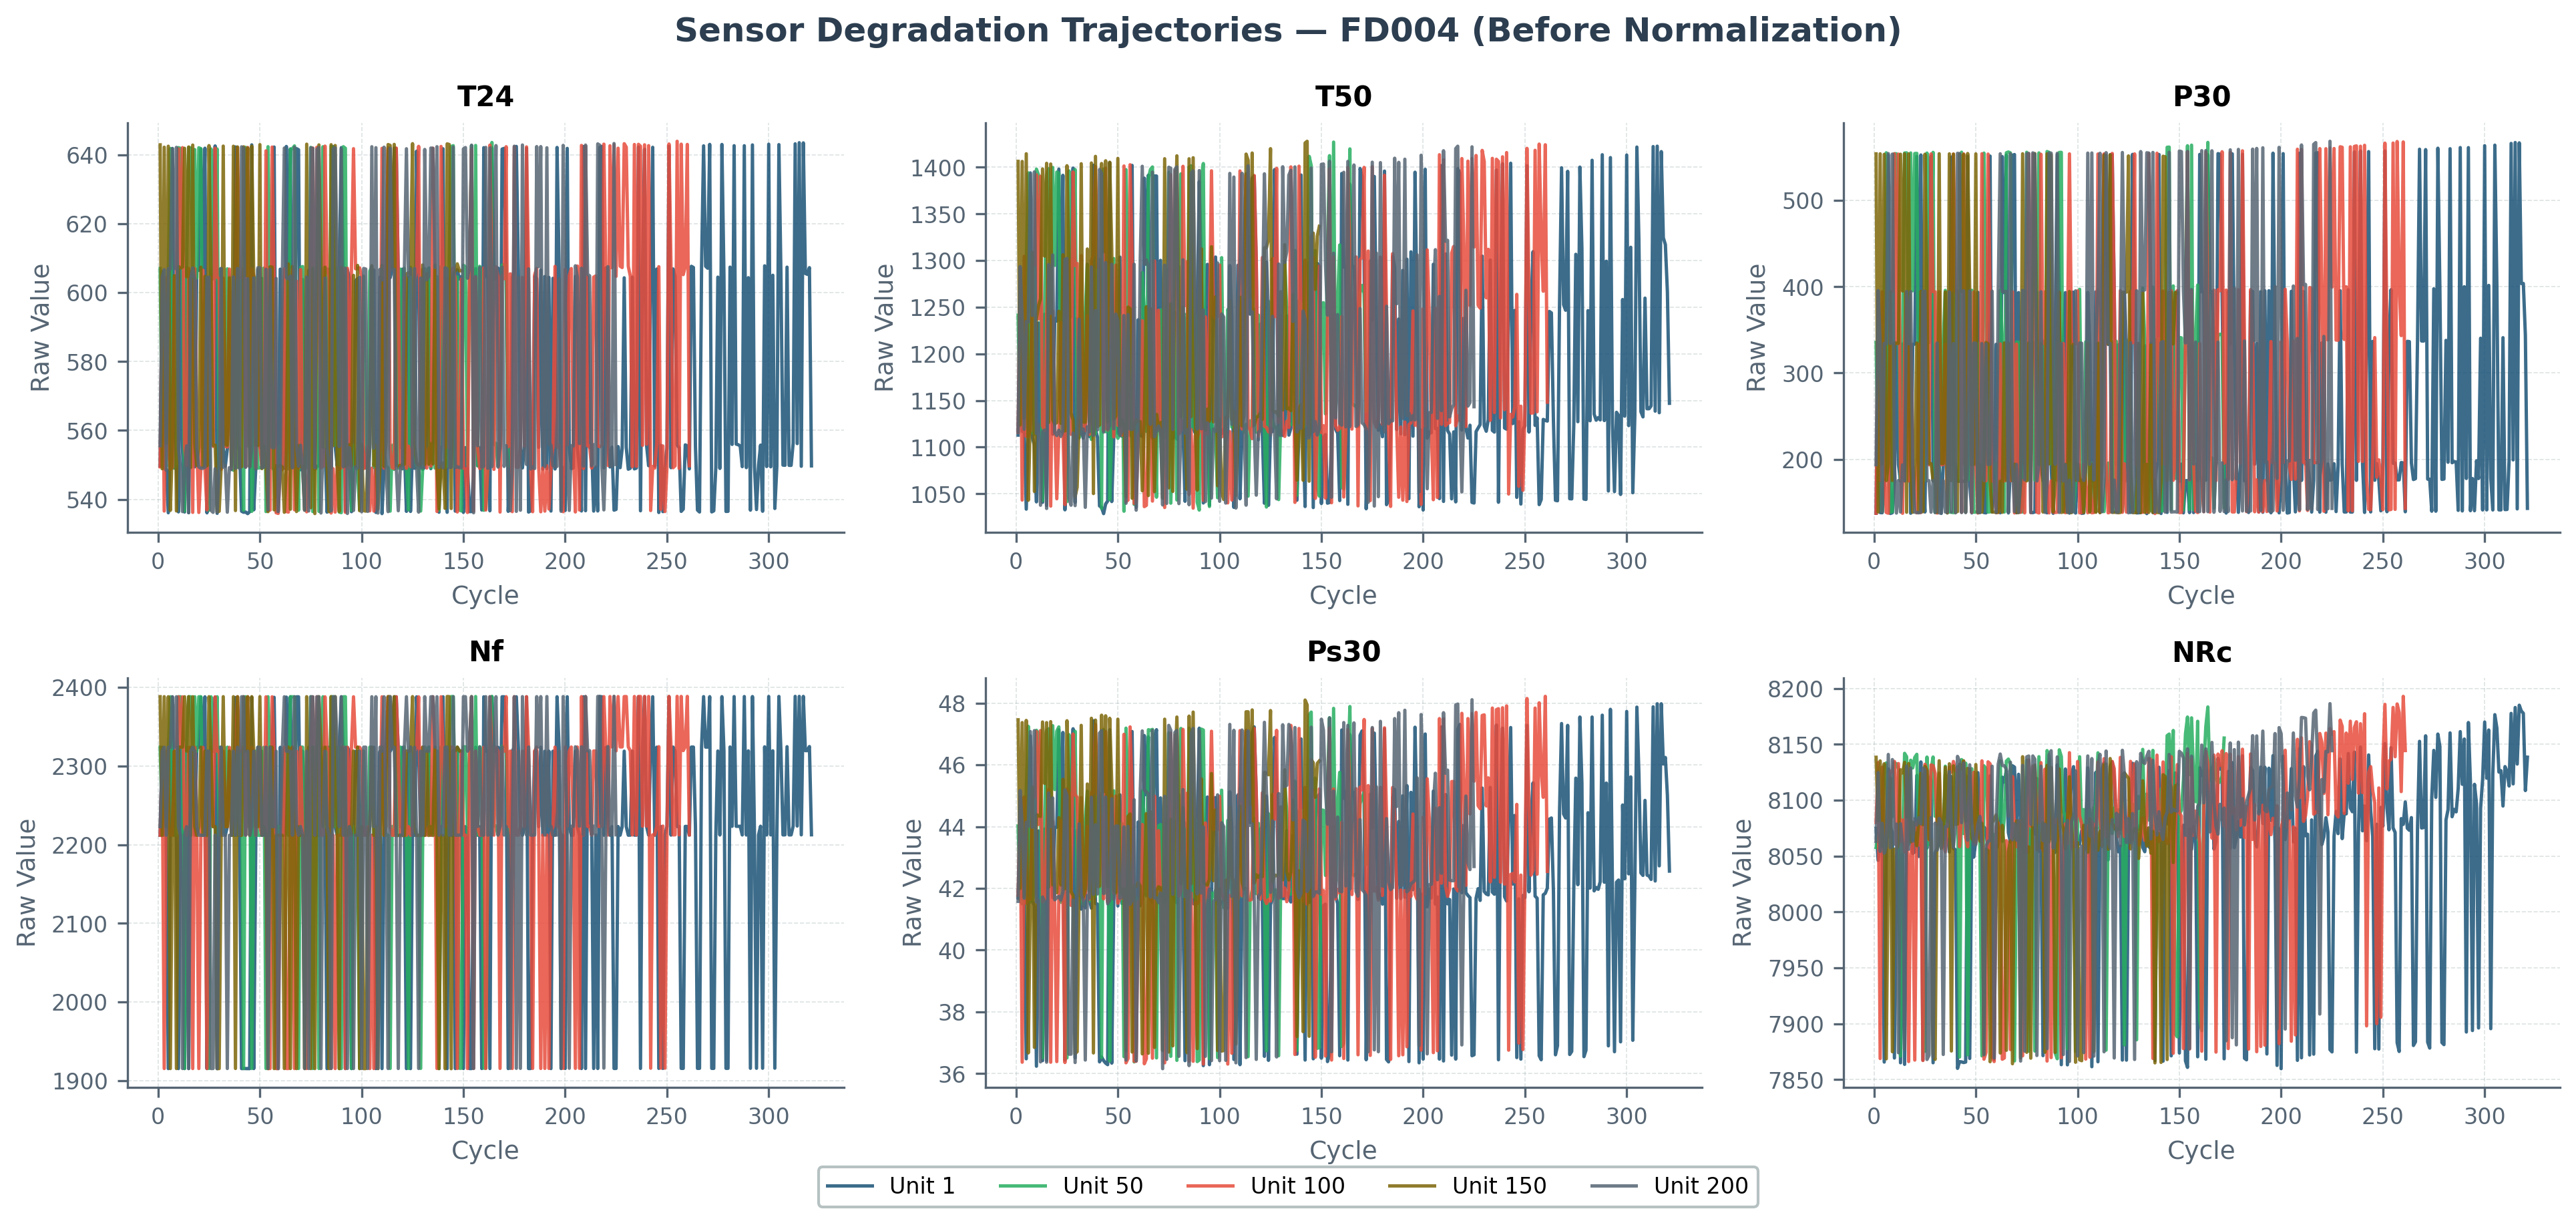

In [14]:
sample_units = [1, 50, 100, 150, 200]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
fig.suptitle('Sensor Degradation Trajectories — FD004 (Before Normalization)',
             fontsize=12, fontweight='bold', color='#2C3E50')

colors_unit = [NAVY, GREEN, RED, AMBER, STEEL]

for ax, sensor in zip(axes.flat, SENSOR_SHOW):
    for uid, col in zip(sample_units, colors_unit):
        subset = train_s[train_s['unit_id'] == uid].sort_values('cycle')
        ax.plot(subset['cycle'], subset[sensor],
                color=col, lw=1.2, alpha=0.85, label=f'Unit {uid}')
    ax.set_title(sensor)
    ax.set_xlabel('Cycle')
    ax.set_ylabel('Raw Value')

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=5,
           fontsize=8, frameon=True, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=[0, 0.04, 1, 1])
save_plot('proc_1_degradation_trajectory_raw.png')
plt.show()

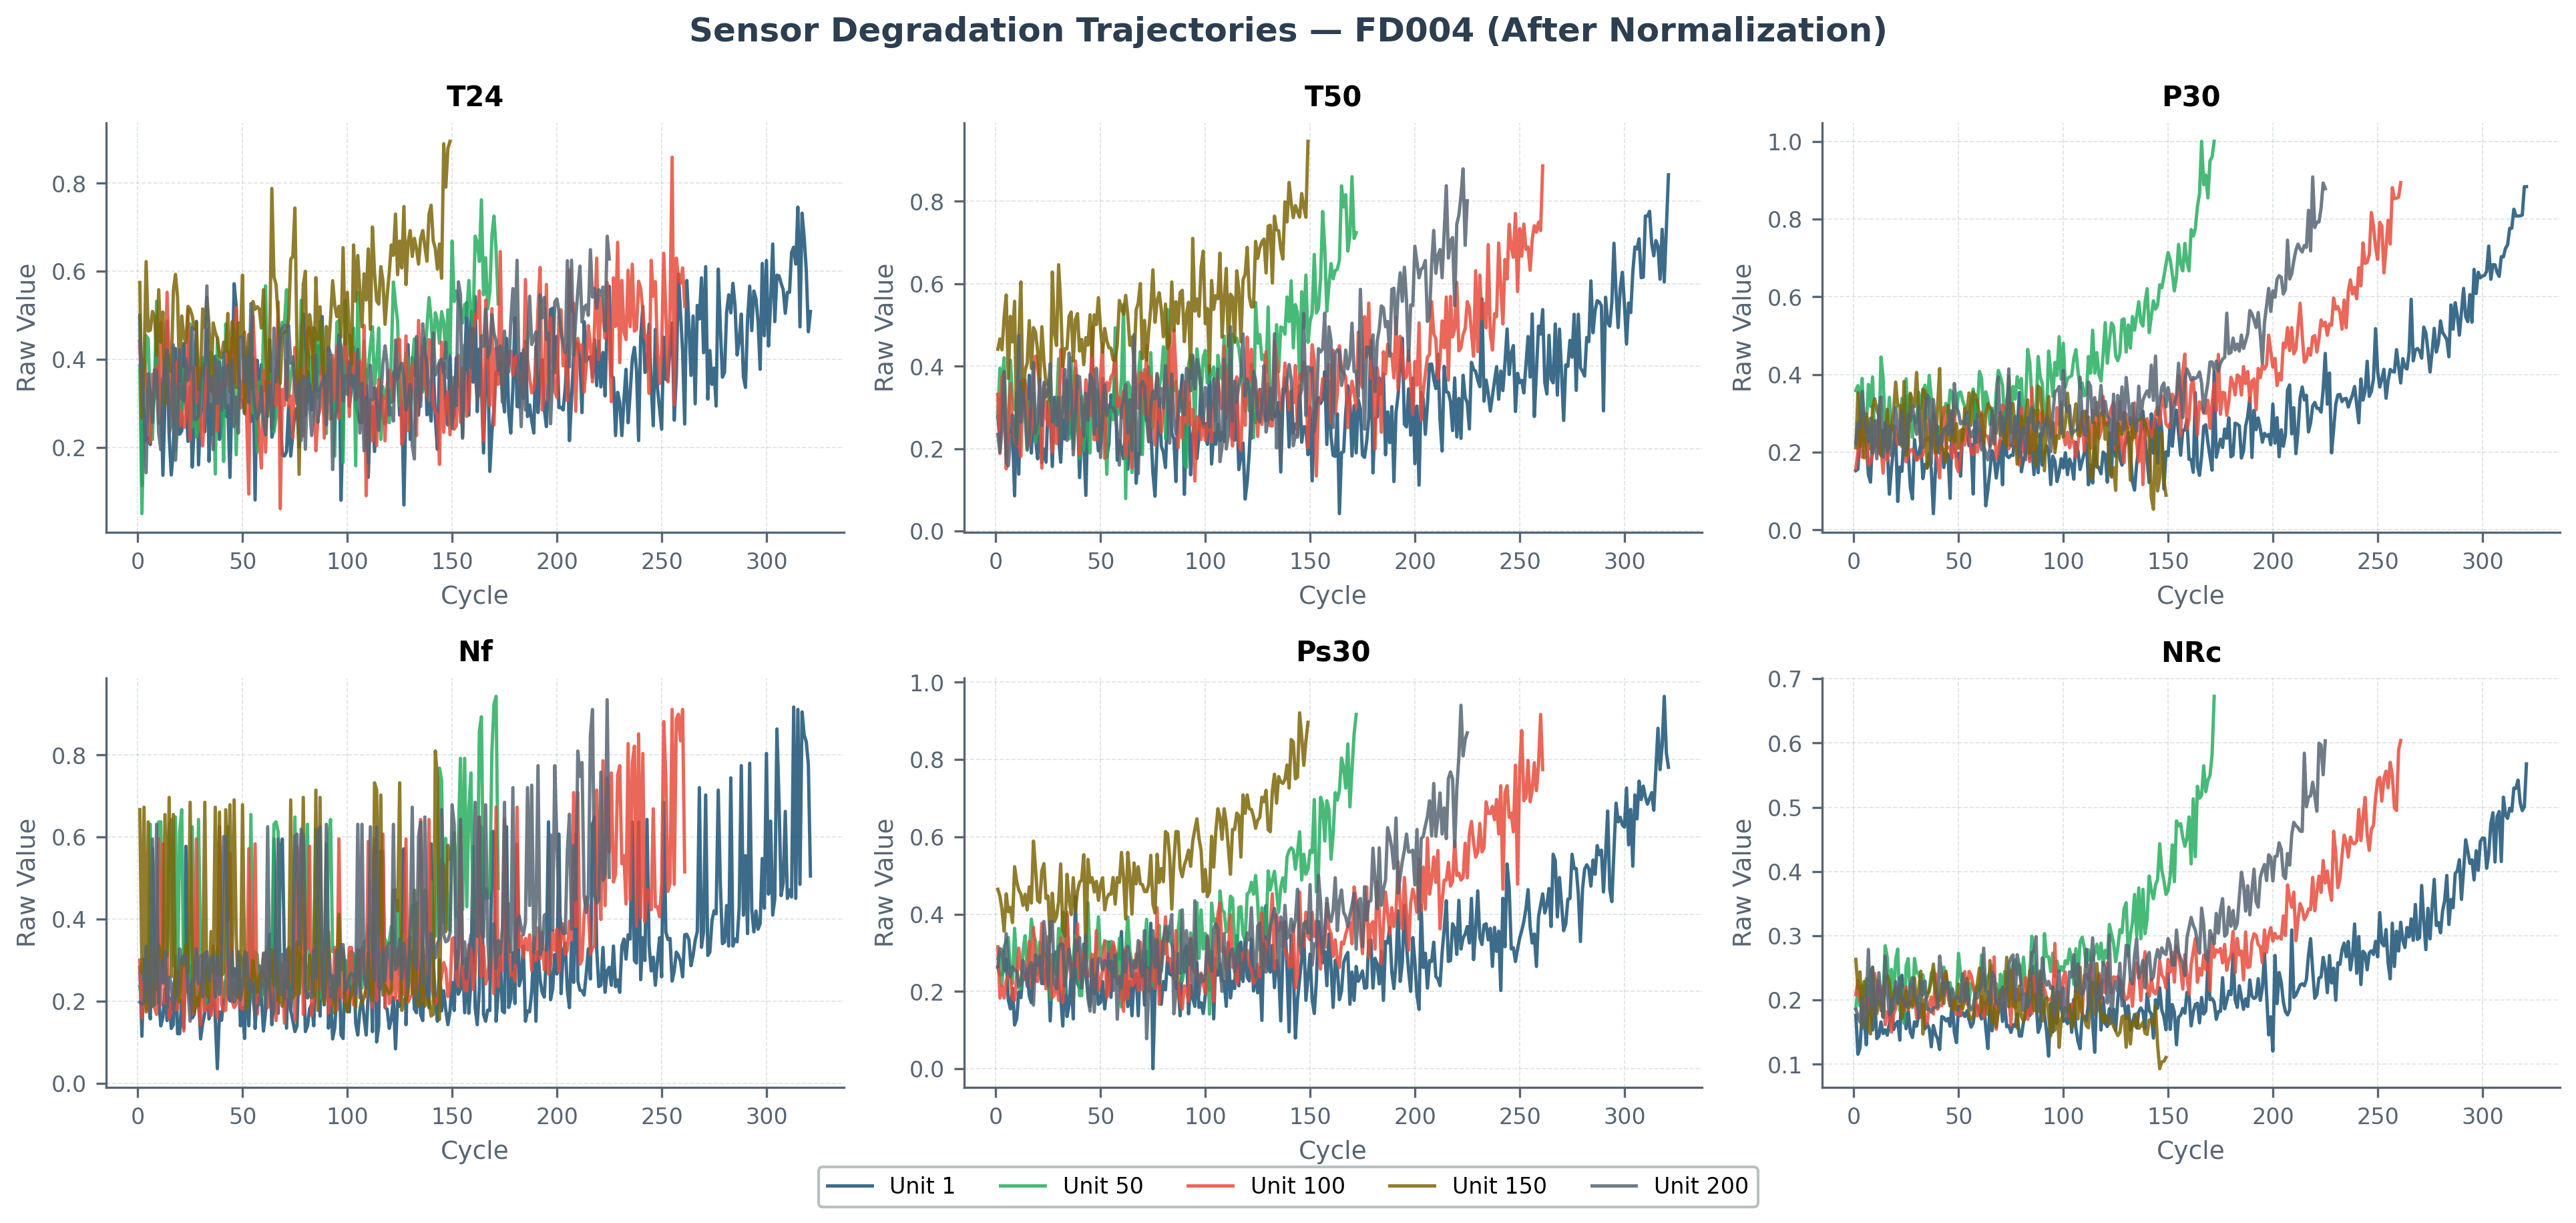

In [15]:
sample_units = [1, 50, 100, 150, 200]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
fig.suptitle('Sensor Degradation Trajectories — FD004 (After Normalization)',
             fontsize=12, fontweight='bold', color='#2C3E50')

colors_unit = [NAVY, GREEN, RED, AMBER, STEEL]

for ax, sensor in zip(axes.flat, SENSOR_SHOW):
    for uid, col in zip(sample_units, colors_unit):
        subset = train_sc[train_sc['unit_id'] == uid].sort_values('cycle')
        ax.plot(subset['cycle'], subset[sensor],
                color=col, lw=1.2, alpha=0.85, label=f'Unit {uid}')
    ax.set_title(sensor)
    ax.set_xlabel('Cycle')
    ax.set_ylabel('Raw Value')

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=5,
           fontsize=8, frameon=True, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=[0, 0.04, 1, 1])
save_plot('proc_1_degradation_trajectory_norm.png')
plt.show()

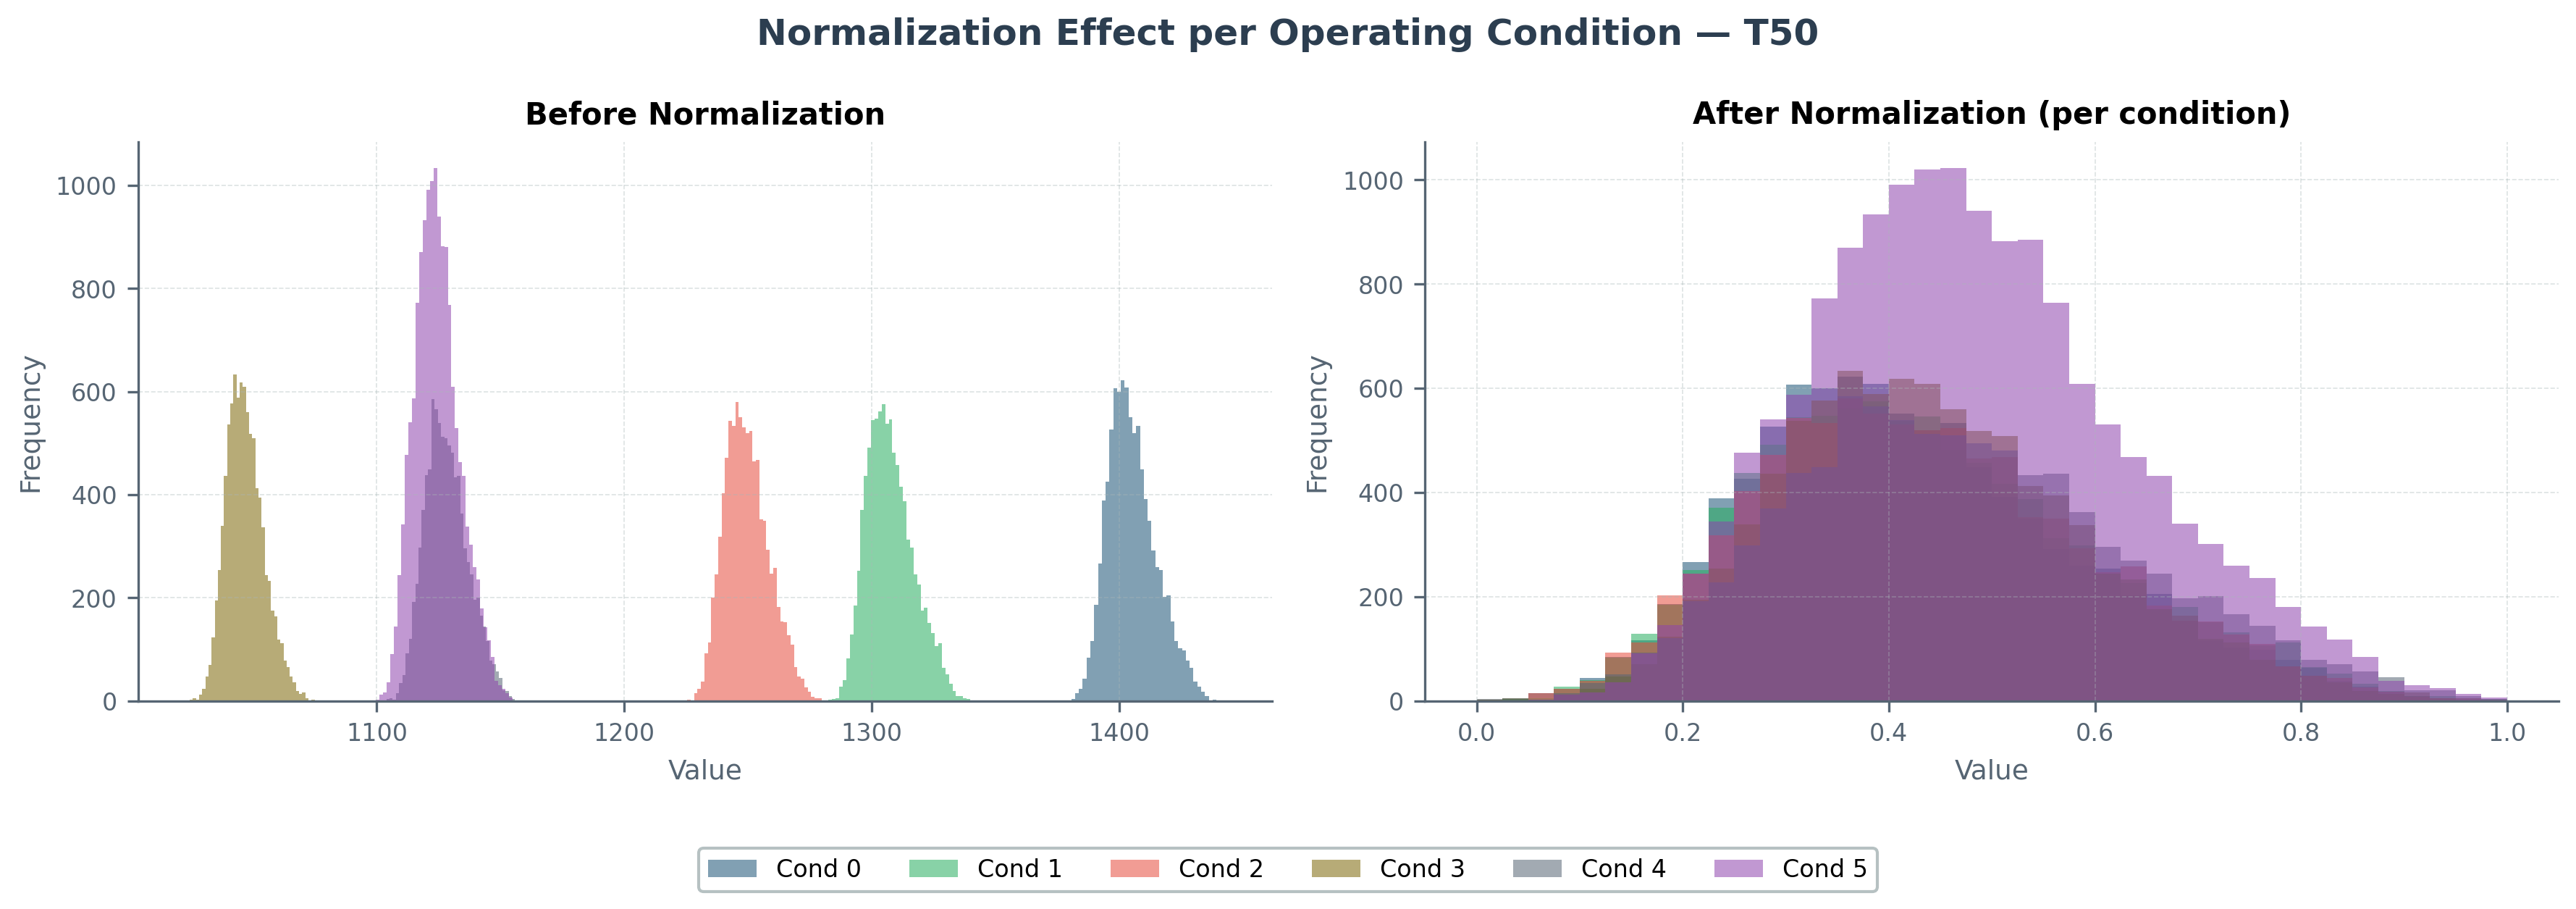

In [16]:
sensor_demo = 'T50'
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle(f'Normalization Effect per Operating Condition — {sensor_demo}',
             fontsize=12, fontweight='bold', color='#2C3E50')

cond_colors = [NAVY, GREEN, RED, AMBER, STEEL, '#8E44AD']

for cond, col in zip(sorted(train_s['op_condition'].unique()), cond_colors):
    subset_raw  = train_s[train_s['op_condition'] == cond]
    subset_norm = train_sc[train_sc['op_condition'] == cond]

    axes[0].hist(subset_raw[sensor_demo],  bins=40, color=col, alpha=0.55, label=f'Cond {cond}')
    axes[1].hist(subset_norm[sensor_demo], bins=40, color=col, alpha=0.55, label=f'Cond {cond}')

axes[0].set_title('Before Normalization')
axes[1].set_title('After Normalization (per condition)')
for ax in axes:
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=6,
           fontsize=8, frameon=True, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=[0, 0.06, 1, 1])
#save_plot('proc_2_normalization_effect.png')
plt.show()

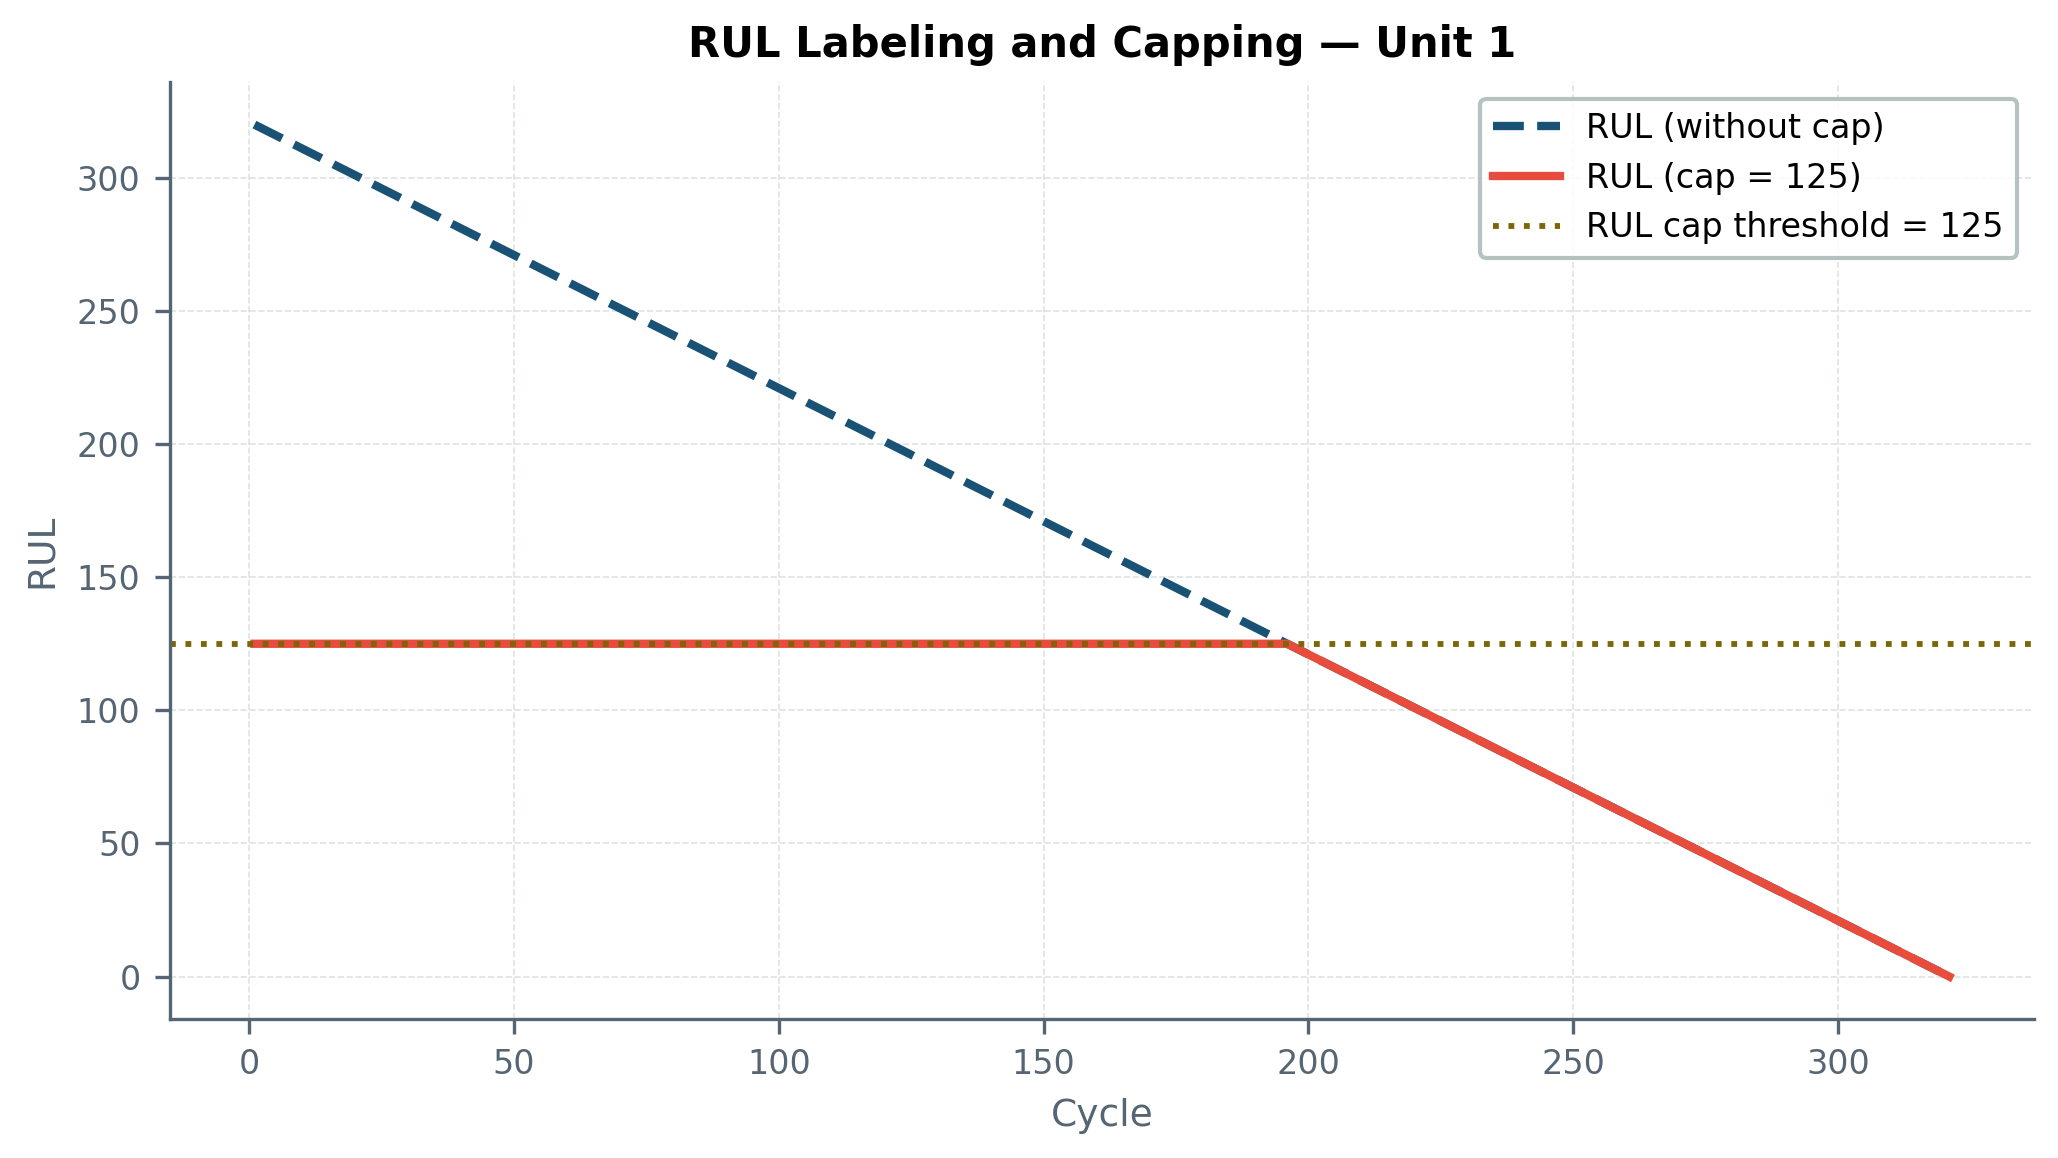

In [17]:
unit_demo = 1
subset = train_s[train_s['unit_id'] == unit_demo].sort_values('cycle').copy()
subset['RUL_raw'] = subset['cycle'].max() - subset['cycle']
subset['RUL_cap'] = subset['RUL_raw'].clip(upper=RUL_CAP)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(subset['cycle'], subset['RUL_raw'], color=NAVY,  lw=2.0,
        label='RUL (without cap)', linestyle='--')
ax.plot(subset['cycle'], subset['RUL_cap'], color=RED,   lw=2.0,
        label=f'RUL (cap = {RUL_CAP})')
ax.axhline(RUL_CAP, color=AMBER, lw=1.4, linestyle=':',
           label=f'RUL cap threshold = {RUL_CAP}')
ax.set_xlabel('Cycle')
ax.set_ylabel('RUL')
ax.set_title(f'RUL Labeling and Capping — Unit {unit_demo}')
ax.legend()
plt.tight_layout()
save_plot('proc_3_rul_labeling_cap.png')
plt.show()

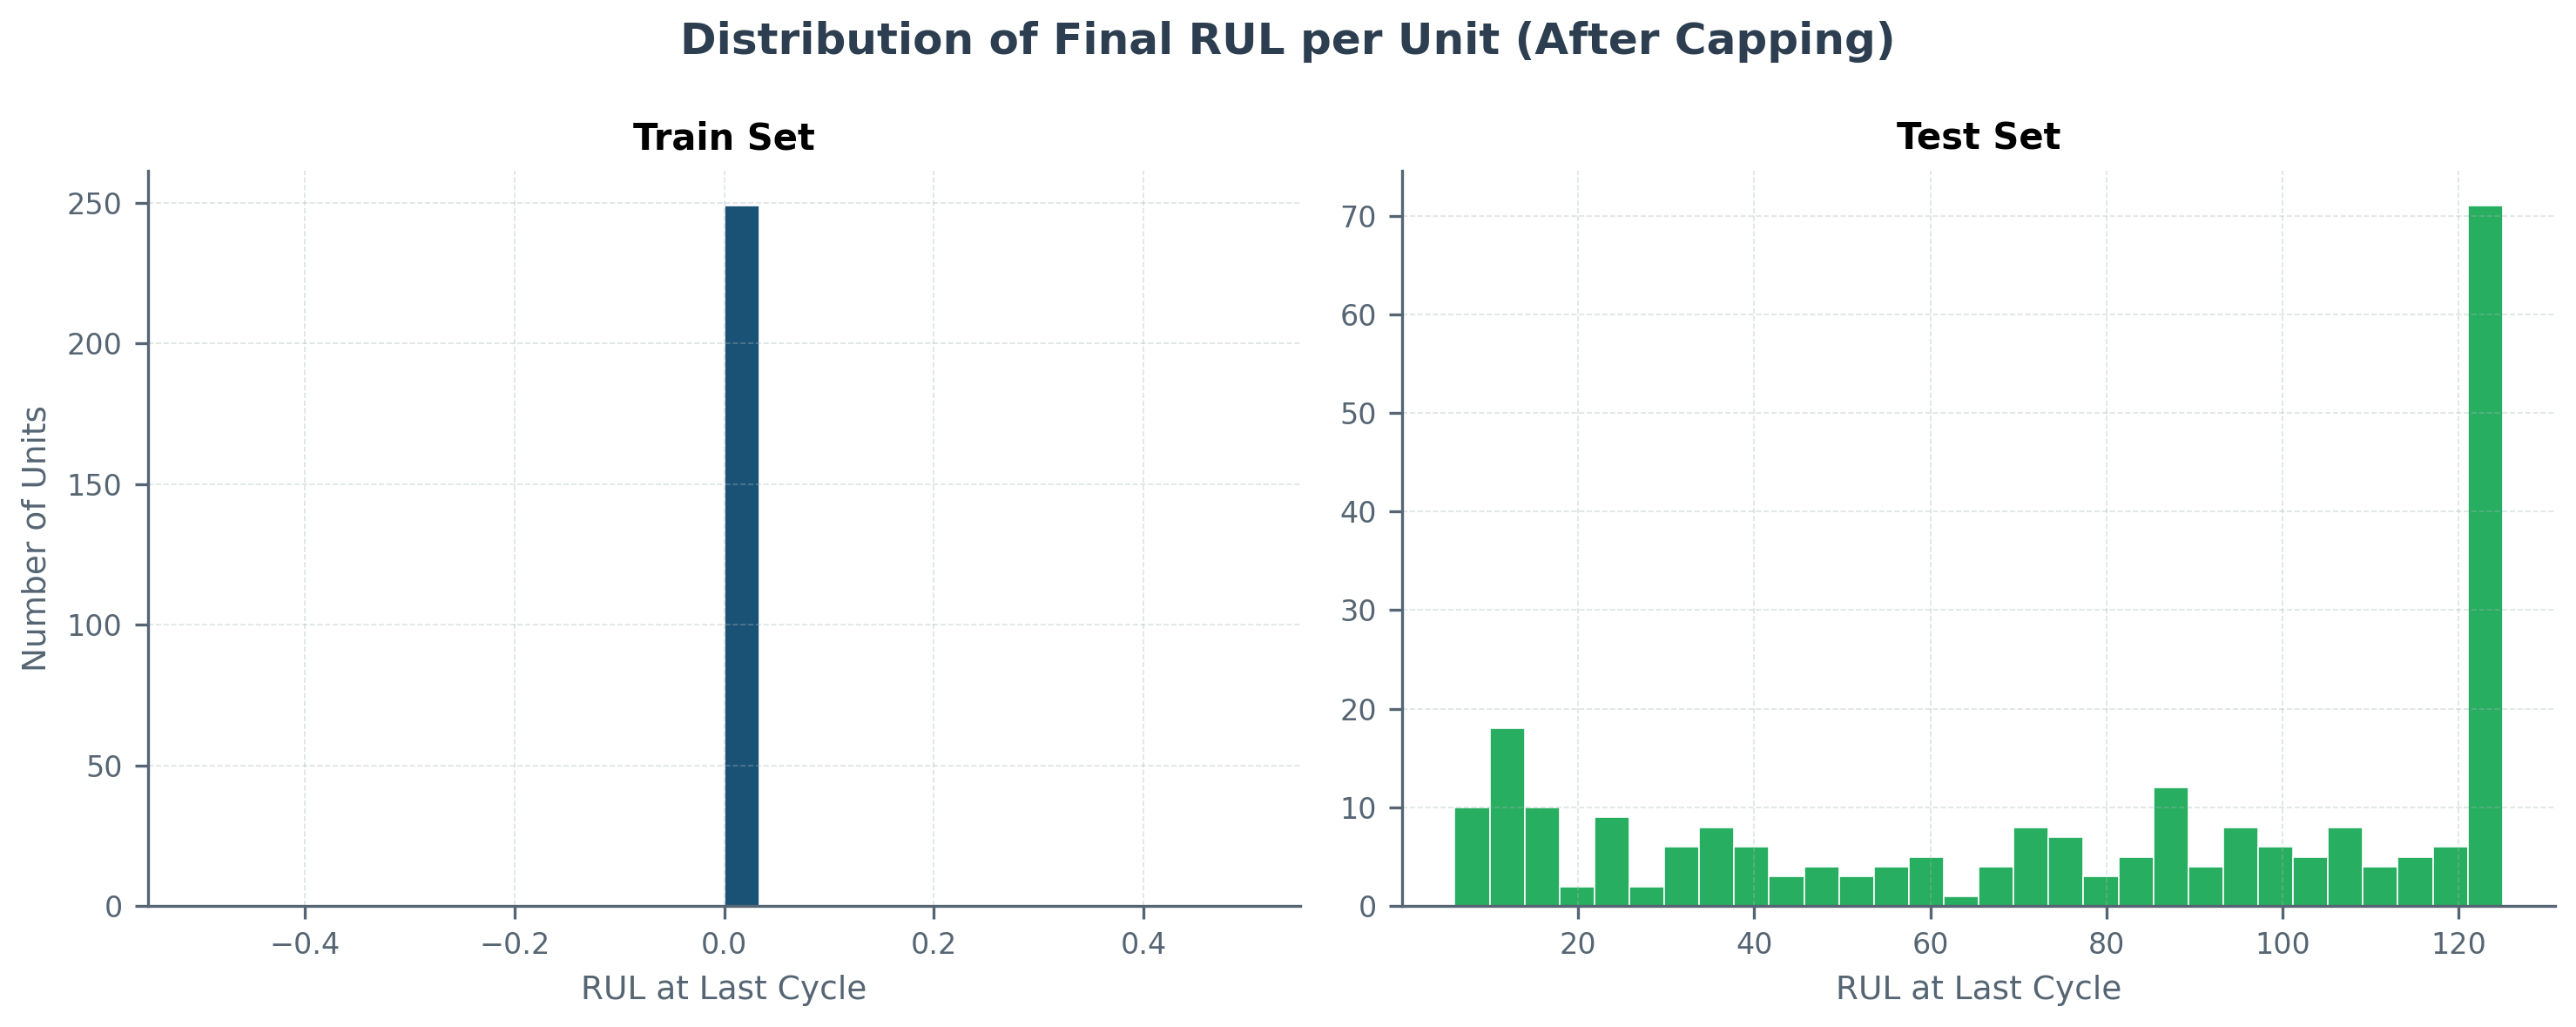

In [18]:
last_train = train_rul_cap.groupby('unit_id')['RUL'].min()
last_test  = test_rul_cap.groupby('unit_id')['RUL'].min()

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
fig.suptitle('Distribution of Final RUL per Unit (After Capping)',
             fontsize=12, fontweight='bold', color='#2C3E50')

axes[0].hist(last_train, bins=30, color=NAVY,  edgecolor='white', linewidth=0.4)
axes[0].set_title('Train Set')
axes[0].set_xlabel('RUL at Last Cycle')
axes[0].set_ylabel('Number of Units')

axes[1].hist(last_test,  bins=30, color=GREEN, edgecolor='white', linewidth=0.4)
axes[1].set_title('Test Set')
axes[1].set_xlabel('RUL at Last Cycle')

plt.tight_layout()
save_plot('proc_4_rul_distribution.png')
plt.show()

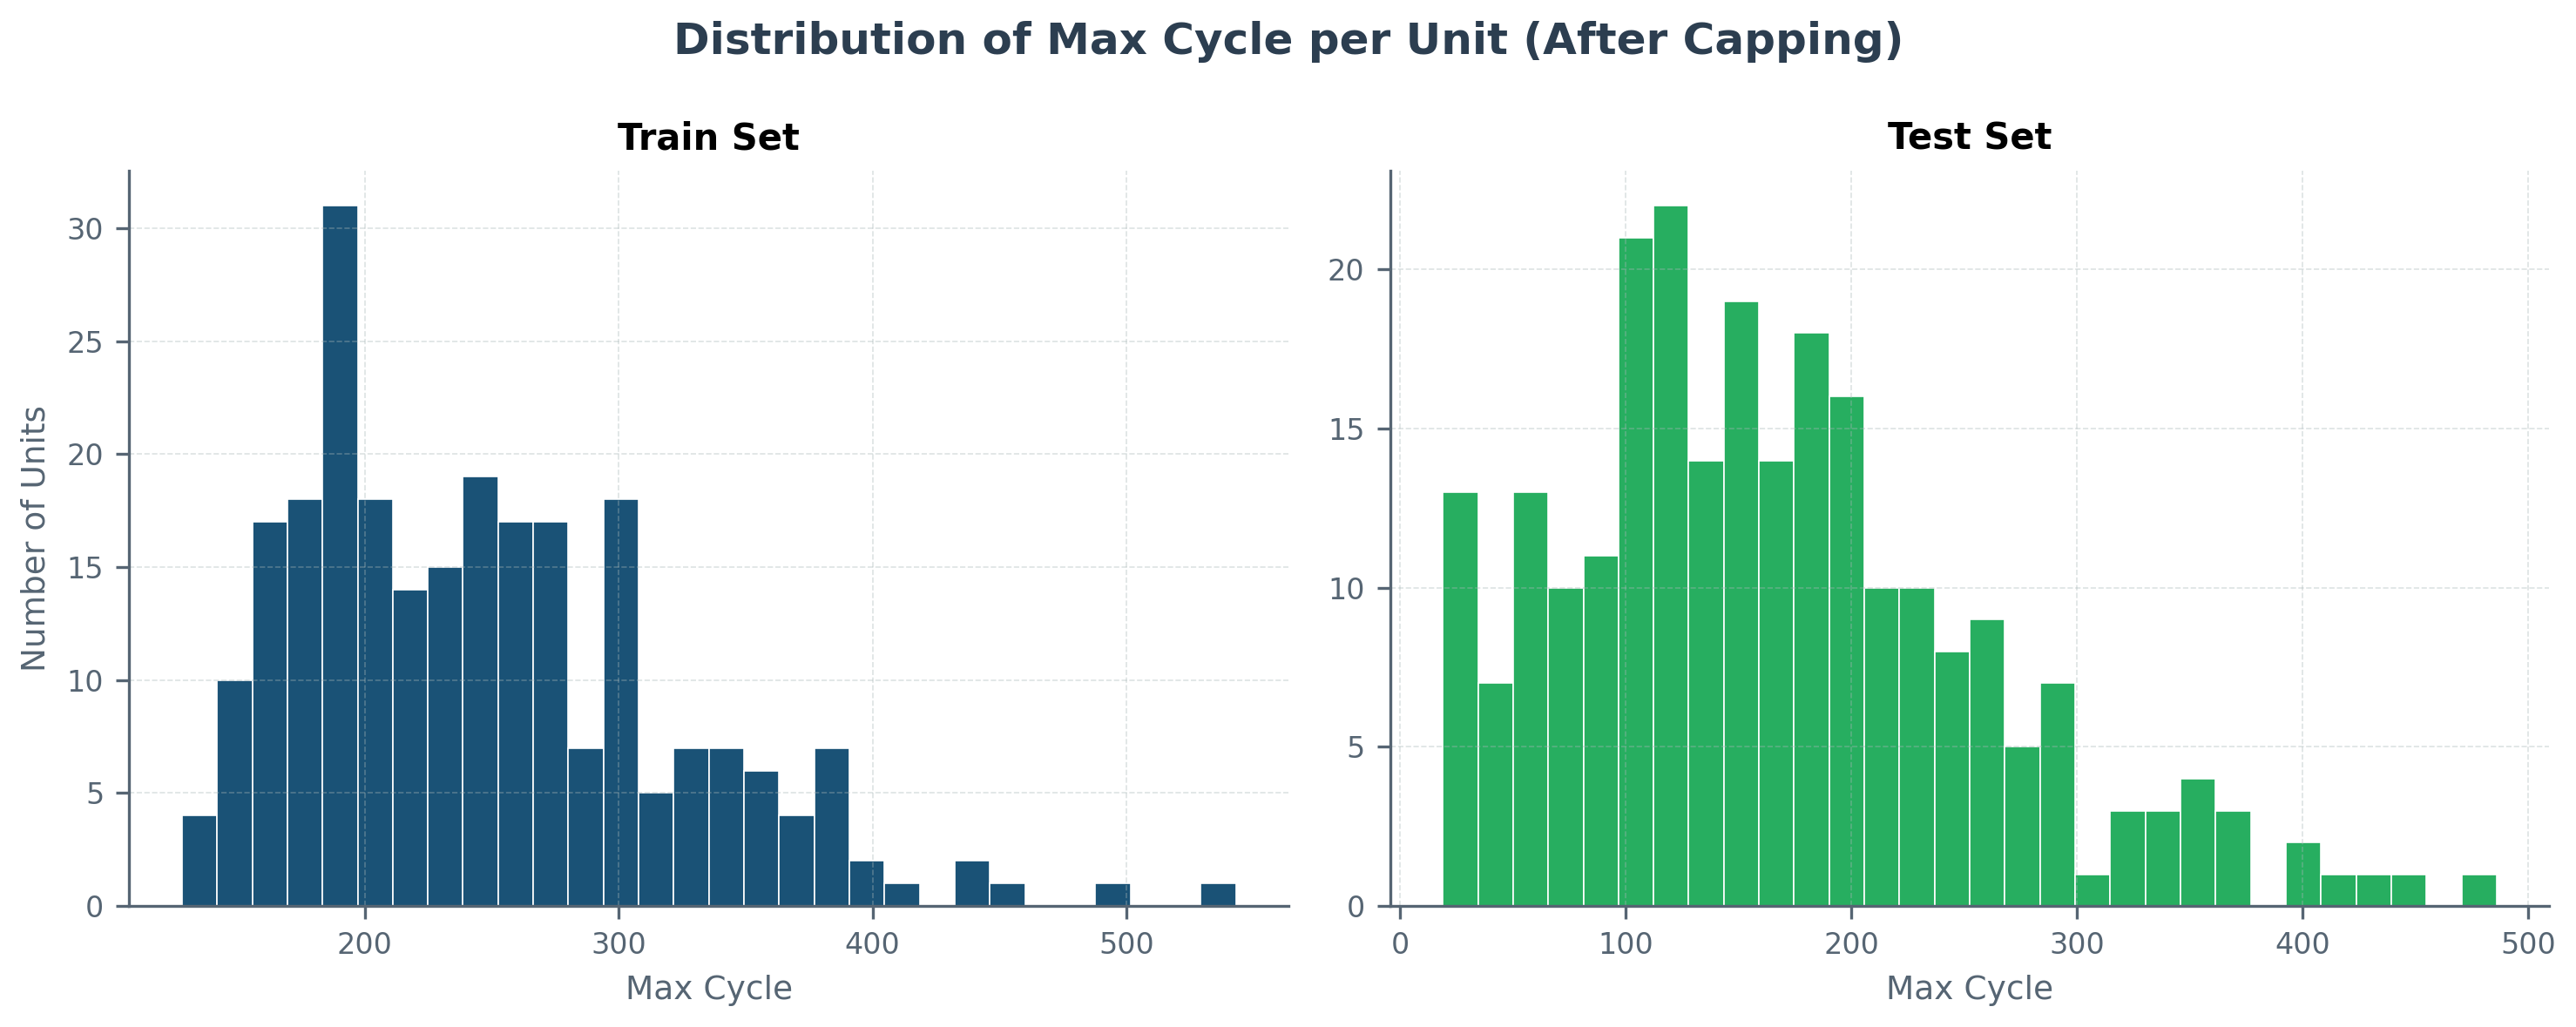

In [19]:
last_train_n = train_sc.groupby('unit_id')['cycle'].max()
last_test_n  = test_sc.groupby('unit_id')['cycle'].max()

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
fig.suptitle('Distribution of Max Cycle per Unit (After Capping)',
             fontsize=12, fontweight='bold', color='#2C3E50')

axes[0].hist(last_train_n, bins=30, color=NAVY,  edgecolor='white', linewidth=0.4)
axes[0].set_title('Train Set')
axes[0].set_xlabel('Max Cycle')
axes[0].set_ylabel('Number of Units')

axes[1].hist(last_test_n,  bins=30, color=GREEN, edgecolor='white', linewidth=0.4)
axes[1].set_title('Test Set')
axes[1].set_xlabel('Max Cycle')

plt.tight_layout()
save_plot('proc_4_maxcycle_distribution_no.png')
plt.show()

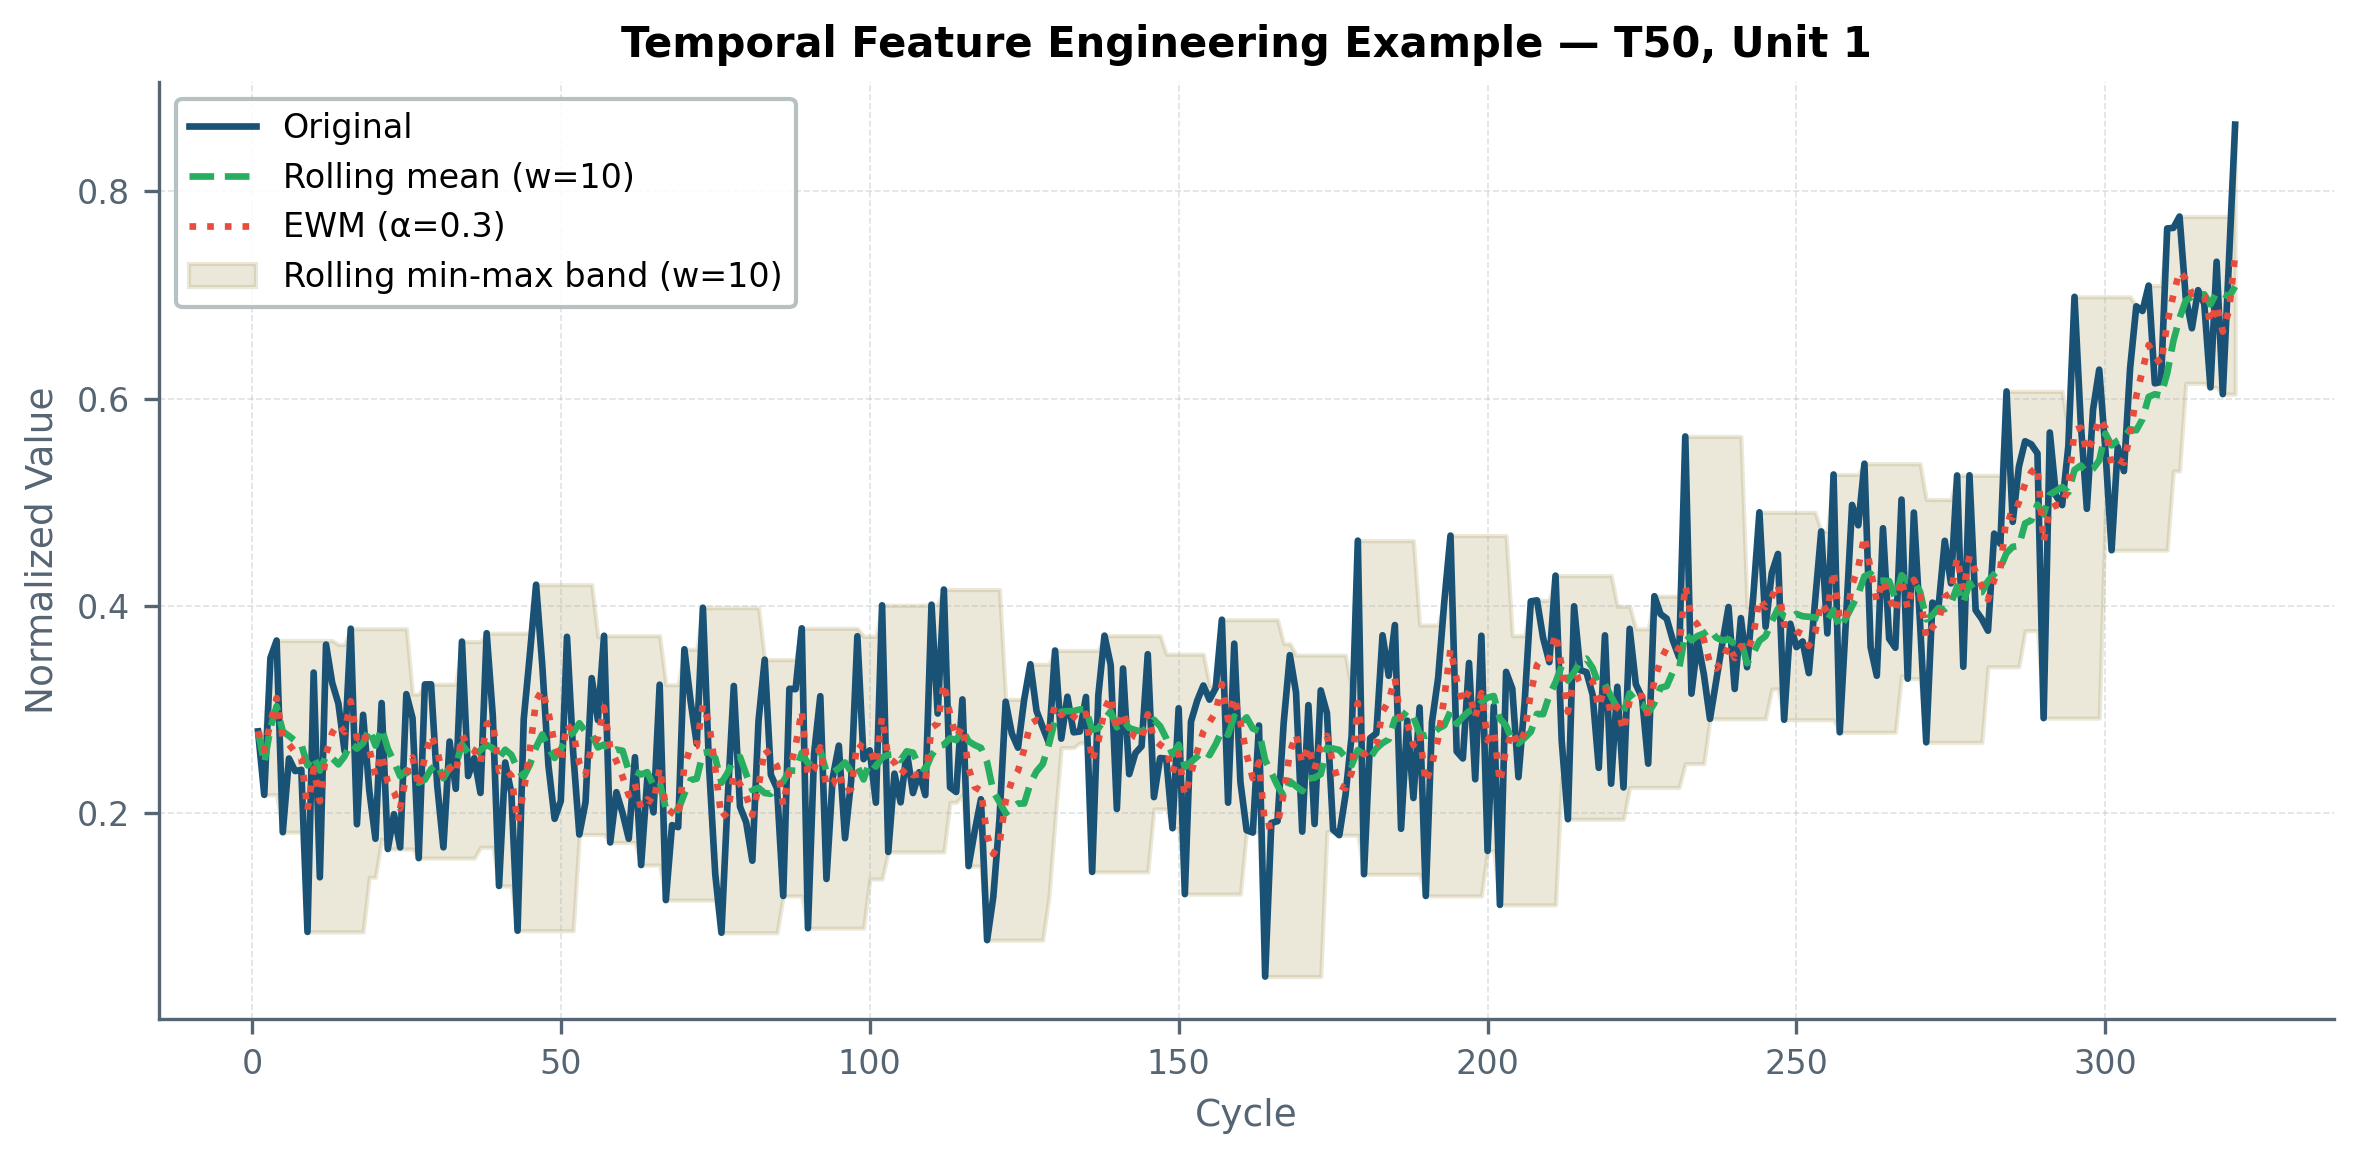

In [20]:
unit_fe   = 1
sensor_fe = 'T50'

subset_fe = train_model[train_model['unit_id'] == unit_fe].sort_values('cycle')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(subset_fe['cycle'], subset_fe[sensor_fe],
        color=NAVY,  lw=1.6, label='Original')
ax.plot(subset_fe['cycle'], subset_fe[f'{sensor_fe}_rmean10'],
        color=GREEN, lw=1.6, linestyle='--', label='Rolling mean (w=10)')
ax.plot(subset_fe['cycle'], subset_fe[f'{sensor_fe}_ewm3'],
        color=RED,   lw=1.6, linestyle=':', label='EWM (α=0.3)')
ax.fill_between(subset_fe['cycle'],
                subset_fe[f'{sensor_fe}_min10'],
                subset_fe[f'{sensor_fe}_max10'],
                color=AMBER, alpha=0.15, label='Rolling min-max band (w=10)')
ax.set_xlabel('Cycle')
ax.set_ylabel('Normalized Value')
ax.set_title(f'Temporal Feature Engineering Example — {sensor_fe}, Unit {unit_fe}')
ax.legend()
plt.tight_layout()
save_plot('proc_5_temporal_features.png')
plt.show()

In [ ]:
Menurut saya **sudah cukup** untuk bagian processing! 5 plot itu sudah mewakili semua keputusan penting.

Sekarang tabelnya. Ingat prinsip yang sama — tabel harus punya alasan, bukan sekadar pajangan data.

---

## Tabel yang WAJIB ada

**Tabel 1 — Karakteristik dataset FD004**

| | Train | Test |
|---|---|---|
| Jumlah unit | 249 | 248 |
| Total cycle | 61.249 | 10.096 |
| Kondisi operasi | 6 | 6 |
| Mode kegagalan | 2 | 2 |
| RUL min (setelah cap) | 0 | 0 |
| RUL max (setelah cap) | 125 | 125 |

**Tabel 2 — Daftar sensor dan keterangan fisiknya**

Pakai `sensor_mapping` lo, tambah kolom satuan dan keterangan singkat. Ini penting karena reviewer aerospace/maintenance perlu tau T50 itu apa.

**Tabel 3 — Rekayasa fitur temporal**

| Fitur | Formula | Tujuan |
|---|---|---|
| `{sensor}_lag1` | nilai t-1 | tangkap perubahan antar cycle |
| `{sensor}_rmean10` | rolling mean w=10 | haluskan noise |
| `{sensor}_ewm3` | EWM α=0.3 | tren terkini lebih berbobot |
| `{sensor}_rstd10` | rolling std w=10 | tangkap volatilitas |
| `{sensor}_max10` | rolling max w=10 | puncak degradasi |
| `{sensor}_min10` | rolling min w=10 | baseline degradasi |

Tambahkan total fitur hasilnya: 21 sensor × 6 fitur + fitur asli = X fitur total.

**Tabel 4 — Skema normalisasi**

| Fitur | Metode | Scope |
|---|---|---|
| Sensor (21 fitur) | MinMaxScaler | Per kondisi operasi |
| Op setting (3 fitur) | MinMaxScaler | Global |

Singkat tapi penting karena justifikasi keputusan lo.

---

## Tabel yang OPSIONAL

**Tabel hyperparameter search space** — bisa masuk Bab 3 metodologi, tunjukkan range RandomizedSearchCV tiap model. Kalau reviewer lo tipe yang detail, ini wajib. Kalau tidak, lampiran saja.

**Tabel hasil CV tiap model** — best params + best CV RMSE dari `search.best_params_` dan `search.best_score_`. Ini masuk Bab 4.

---

## Yang TIDAK perlu dijadikan tabel

- List nama semua fitur temporal (126+ fitur) → cukup sebut jumlahnya di teks
- Nilai scaler min/max per kondisi → tidak ada nilainya buat pembaca
- Semua nilai hyperparameter hasil tuning secara lengkap → lampiran saja

---

Jadi total untuk bagian dataset + processing: **5 plot + 4 tabel**. Cukup padat tapi tidak berlebihan. Mau lanjut ke saran visualisasi dan tabel untuk bagian **pelatihan model dan hasil**?